# Exercise 3: Neural networks in PyTorch

In this exercise you’ll implement small neural-network building blocks from scratch and use them to train a simple classifier.

You’ll cover:
- **Basic layers**: Linear, Embedding, Dropout
- **Normalization**: LayerNorm and RMSNorm
- **MLPs + residual**: composing layers into deeper networks
- **Classification**: generating a learnable dataset, implementing cross-entropy from logits, and writing a minimal training loop

As before: fill in all `TODO`s without changing function names or signatures.
Use small sanity checks and compare to PyTorch reference implementations when useful.

In [1]:
from __future__ import annotations

import torch
from torch import nn

## Basic layers

In this section you’ll implement a few core layers that appear everywhere:

### `Linear`
A fully-connected layer that follows nn.Linear conventions:  
`y = x @ Wᵀ + b`

Important details:
- Parameters should be registered as `nn.Parameter`
- Store weight as (out_features, in_features) like nn.Linear.
- The forward pass should support leading batch dimensions: `x` can be shape `(..., in_features)`

### `Embedding`
An embedding table maps integer ids to vectors:
- input: token ids `idx` of shape `(...,)`
- output: vectors of shape `(..., embedding_dim)`

This is essentially a learnable lookup table.

### `Dropout`
Dropout randomly zeroes activations during training to reduce overfitting.
Implementation details:
- Only active in `model.train()` mode
- In training: drop with probability `p` and scale the kept values by `1/(1-p)` so the expected value stays the same
- In eval: return the input unchanged

## Instructions
- Do not use PyTorch reference modules for the parts you implement (e.g. don’t call nn.Linear inside your Linear).
- You may use standard tensor ops that you learned before (matmul, sum, mean, rsqrt, indexing, etc.).
- Use a parameter initialization method of your choice. We recommend something like Xavier-uniform.


In [2]:
class Linear(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias: bool = True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(out_features, in_features))
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None
        nn.init.xavier_uniform_(self.weight)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (..., in_features)
        return: (..., out_features)
        """
        out = x @ self.weight.transpose(0, 1)
        return out if self.bias is None else out + self.bias

In [3]:
class Embedding(nn.Module):
    def __init__(self, num_embeddings: int, embedding_dim: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(num_embeddings, embedding_dim))
        nn.init.normal_(self.weight)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """
        idx: (...,) int64
        return: (..., embedding_dim)
        """
        return self.weight[idx]

In [4]:
class Dropout(nn.Module):
    def __init__(self, p: float):
        super().__init__()
        if not 0 <= p <= 1:
            raise ValueError("p must be between 0 and 1")
        self.p = p

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        In train mode: drop with prob p and scale by 1/(1-p).
        In eval mode: return x unchanged.
        """
        if not self.training or self.p == 0:
            return x
        if self.p == 1:
            return x * 0
        keep = torch.rand_like(x) >= self.p
        return x * keep.to(dtype=x.dtype) / (1 - self.p)

## Normalization

Normalization layers help stabilize training by controlling activation statistics.

### LayerNorm
LayerNorm normalizes each example across its **feature dimension** (the last dimension):

- compute mean and variance over the last dimension
- normalize: `(x - mean) / sqrt(var + eps)`
- apply learnable per-feature scale and shift (`weight`, `bias`)

**In this exercise, assume `elementwise_affine=True` (always include `weight` and `bias`).**  
`weight` and `bias` each have shape `(D,)`.

LayerNorm is widely used in transformers because it does not depend on batch statistics.

### RMSNorm
RMSNorm is similar to LayerNorm but normalizes using only the root-mean-square:
- `x / sqrt(mean(x^2) + eps)` over the last dimension
- usually includes a learnable scale (`weight`)
- no mean subtraction

RMSNorm is popular in modern LLMs because it's faster.


In [5]:
class LayerNorm(nn.Module):
    def __init__(
        self, normalized_shape: int, eps: float = 1e-5, elementwise_affine: bool = True
    ):
        super().__init__()
        self.eps = eps
        if elementwise_affine:
            self.weight = nn.Parameter(torch.ones(normalized_shape))
            self.bias = nn.Parameter(torch.zeros(normalized_shape))
        else:
            self.register_parameter("weight", None)
            self.register_parameter("bias", None)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Normalize over the last dimension.
        x: (..., D)
        """
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        out = (x - mean) * torch.rsqrt(var + self.eps)
        return out if self.weight is None else out * self.weight + self.bias

In [6]:
class RMSNorm(nn.Module):
    def __init__(self, normalized_shape: int, eps: float = 1e-8):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(normalized_shape))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        RMSNorm: x / sqrt(mean(x^2) + eps) * weight
        over the last dimension.
        """
        return x * torch.rsqrt(x.square().mean(dim=-1, keepdim=True) + self.eps) * self.weight

## MLPs and residual networks

Now you’ll build larger networks by composing layers.

### MLP
An MLP is a stack of `depth` Linear layers with non-linear activations (use GELU) in between.
In this exercise you’ll support:
- configurable depth
- a hidden dimension
- optional LayerNorm between layers (a common stabilization trick)

A key skill is building networks using `nn.ModuleList` / `nn.Sequential` while keeping shapes consistent.

### Transformer-style FeedForward (FFN)
A transformer block contains a position-wise feedforward network:
- `D -> 4D -> D` (by default)
- activation is typically **GELU**

This is essentially an MLP applied independently at each token position.

### Residual wrapper
Residual connections are the simplest form of “skip connection”:
- output is `x + fn(x)`

They improve gradient flow and allow training deeper networks more reliably.

In [7]:
class MLP(nn.Module):
    def __init__(
        self,
        in_dim: int,
        hidden_dim: int,
        out_dim: int,
        depth: int,
        use_layernorm: bool = False,
    ):
        super().__init__()
        if depth < 1:
            raise ValueError("depth is the number of Linear layers and must be >= 1")
        dims = [in_dim] + [hidden_dim] * (depth - 1) + [out_dim]
        layers = []
        for i in range(depth):
            layers.append(Linear(dims[i], dims[i + 1]))
            if i < depth - 1:
                if use_layernorm:
                    layers.append(LayerNorm(dims[i + 1]))
                layers.append(nn.GELU())
        self.layers = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)

In [8]:
class FeedForward(nn.Module):
    """
    Transformer-style FFN: D -> 4D -> D (default)
    """

    def __init__(self, d_model: int, d_ff: int | None = None):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.layers = nn.Sequential(Linear(d_model, d_ff), nn.GELU(), Linear(d_ff, d_model))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)

In [9]:
class Residual(nn.Module):
    def __init__(self, fn: nn.Module):
        super().__init__()
        self.fn = fn

    def forward(self, x: torch.Tensor, *args, **kwargs) -> torch.Tensor:
        return x + self.fn(x, *args, **kwargs)

## Classification problem

In this section you’ll put everything together in a minimal MNIST classification experiment.

You will:
1) download and load the MNIST dataset
2) implement cross-entropy from logits (stable, using log-softmax)
3) build a simple MLP-based classifier (flatten MNIST images first)
4) write a minimal training loop
5) report train loss curve and final accuracy

The goal here is not to reach state-of-the-art accuracy, but to understand the full pipeline:
data → model → logits → loss → gradients → parameter update.

### Model notes
- We want you to combine the MLP we implemented above with the classification head we define below into one model 

### MNIST notes
- MNIST images are `28×28` grayscale.
- After `ToTensor()`, each image has shape `(1, 28, 28)` and values in `[0, 1]`.
- For an MLP classifier, we flatten to a vector of length `784`.

## Deliverables
- Include a plot of your train loss curve in the video submission as well as a final accuracy. 
- **NOTE** Here we don't grade on model performance but we expect you to achieve at least 70% accuracy to confirm a correct model implementation.

In [10]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [11]:
transform = transforms.ToTensor()
train_ds = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST(root="data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(0))
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=0)

In [12]:
def cross_entropy_from_logits(
    logits: torch.Tensor,
    targets: torch.Tensor,
) -> torch.Tensor:
    """
    Compute mean cross-entropy loss from logits.

    logits: (B, C)
    targets: (B,) int64

    Requirements:
    - Use log-softmax for stability (do not use torch.nn.CrossEntropyLoss, we check this in the autograder).
    """
    log_probs = torch.log_softmax(logits, dim=-1)
    return -log_probs.gather(1, targets.unsqueeze(1)).mean()

In [13]:
class ClassificationHead(nn.Module):
    def __init__(self, d_in: int, num_classes: int):
        super().__init__()
        self.projection = Linear(d_in, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (..., d_in)
        return: (..., num_classes) logits
        """
        return self.projection(x)

In [14]:
def evaluate_classifier(model: nn.Module, loader: DataLoader) -> tuple[float, float]:
    """Sample-weighted mean loss and accuracy; preserve the incoming model mode."""
    was_training = model.training
    model.eval()
    device = next(model.parameters()).device
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += cross_entropy_from_logits(logits, yb).item() * yb.numel()
            correct += (logits.argmax(dim=-1) == yb).sum().item()
            total += yb.numel()
    model.train(was_training)
    if total == 0:
        raise ValueError("Cannot evaluate an empty loader")
    return total_loss / total, correct / total


def accuracy(loader):
    """Evaluate the notebook's model; signature follows the assignment template."""
    return evaluate_classifier(model, loader)[1]

In [15]:
def train_classifier(
    model: nn.Module,
    train_data_loader: DataLoader,
    test_data_loader: DataLoader,
    lr: float,
    epochs: int,
    seed: int = 0,
) -> list[float]:
    """
    Minimal training loop for MNIST classification.

    Steps:
    - define optimizer
    - for each epoch:
        - sample minibatches
        - forward -> cross-entropy -> backward -> optimizer step
      - compute test accuracy at the end of each epoch
    - return list of training losses (one per update step)

    Requirements:
    - call model.train() during training and model.eval() during evaluation
    - do not use torch.nn.CrossEntropyLoss (use your cross_entropy_from_logits)
    """
    torch.manual_seed(seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    device = next(model.parameters()).device
    losses = []
    history = {"train_losses": losses, "train_epoch_losses": [],
               "test_losses": [], "test_accs": []}
    for epoch in range(epochs):
        model.train()
        total_loss, total = 0.0, 0
        for xb, yb in train_data_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = cross_entropy_from_logits(model(xb), yb)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            total_loss += loss.item() * yb.numel()
            total += yb.numel()
        test_loss, test_acc = evaluate_classifier(model, test_data_loader)
        history["train_epoch_losses"].append(total_loss / max(total, 1))
        history["test_losses"].append(test_loss)
        history["test_accs"].append(test_acc)
        print(f"Epoch {epoch + 1}/{epochs}: test loss={test_loss:.4f}, accuracy={test_acc:.2%}")
    model.training_history = history
    return losses

Epoch 1/3: test loss=0.1158, accuracy=96.18%
Epoch 2/3: test loss=0.0887, accuracy=97.05%
Epoch 3/3: test loss=0.0795, accuracy=97.26%
Final test accuracy: 97.26%


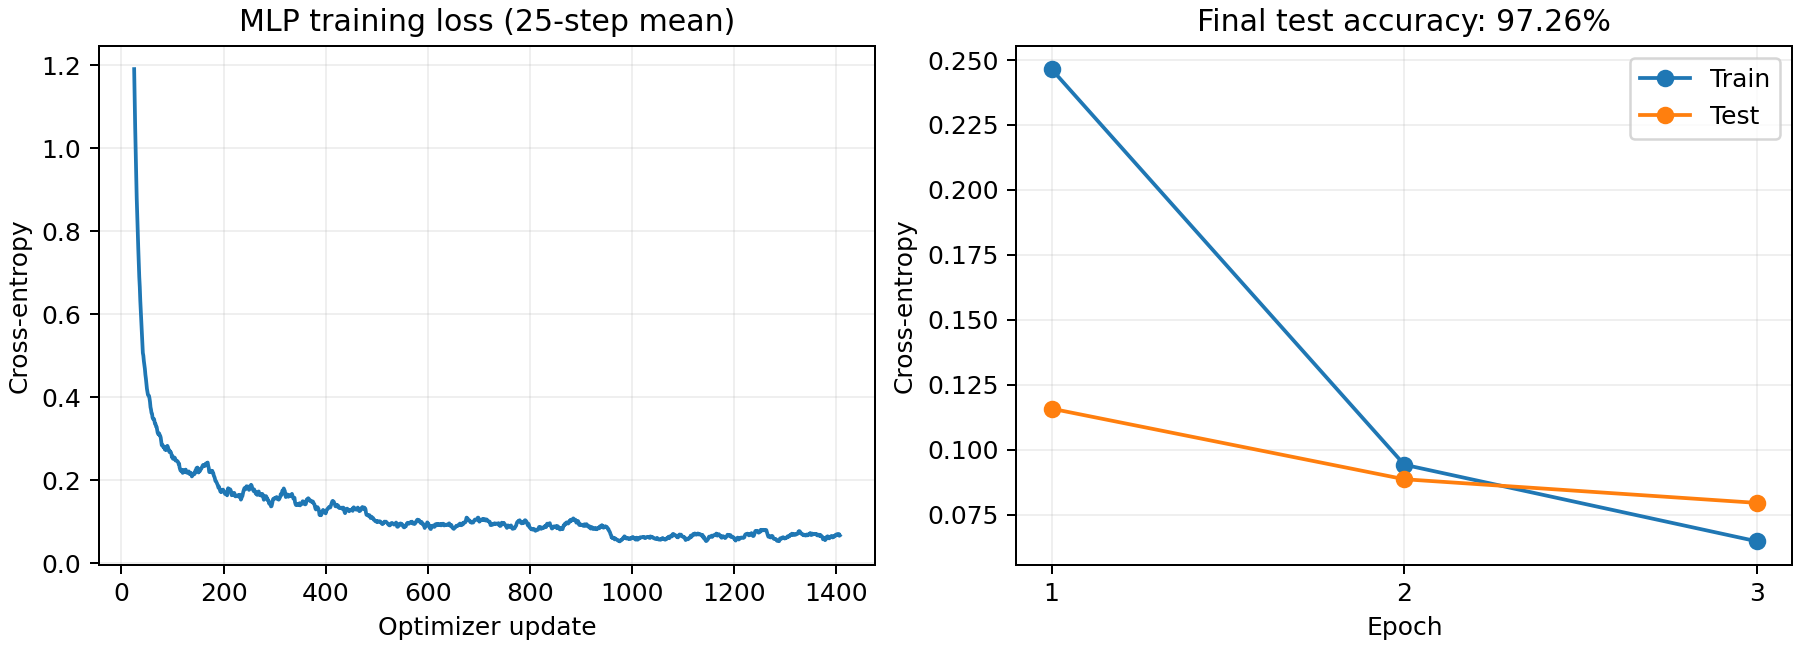

In [16]:
# Seed BEFORE constructing the model to make its initialization reproducible.
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = nn.Sequential(
    nn.Flatten(start_dim=1),
    MLP(784, 128, 128, depth=2, use_layernorm=True),
    nn.GELU(),
    ClassificationHead(128, 10),
).to(device)
train_losses = train_classifier(model, train_loader, test_loader, lr=1e-3, epochs=3, seed=0)
print(f"Final test accuracy: {accuracy(test_loader):.2%}")

# Standard-library JSON keeps plotting dependencies out of the submitted notebook.
import json
from pathlib import Path
Path("results").mkdir(exist_ok=True)
Path("results/ex3_metrics.json").write_text(json.dumps(model.training_history, indent=2))

### Reading the experiment
The sample-weighted train and test losses are recorded after each epoch; training losses
are also recorded after every update. Run `python plot_results.py` from the homework
directory to create the loss curves for your slides. Compare the train/test gap and
report the final held-out accuracy. The 70% requirement is a correctness check, not a
reason to tune repeatedly on the test set.